# 06 社区发现与攻击鲁棒性

两块内容都属于「结构分析」，但回答的问题不同：

| 子包 | 问题 | 输入 |
| --- | --- | --- |
| `honet.community` | 这张超图能切成几块？切得干净吗？ | **hypernetx** 超图 |
| `honet.attack` | 删掉哪些结点会让网络崩得最快？ | **hypernetx** 超图 |

> **输入类型**：和 `metrics` / `contagion` 一样，两者都收 hypernetx 超图。

In [1]:
import warnings

import hypernetx as hnx
import matplotlib.pyplot as plt

import honet

# hypernetx 2.4.3 内部 pd.concat 会刷 FutureWarning，与本示例无关，屏蔽掉
warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# 刻意做成"两个稠密社区 + 一条细桥"：
#   - 社区 A：a/b/c 频繁合作（3 条超边）
#   - 社区 B：d/e/f 频繁合作（3 条超边）
#   - 桥：c-d 只出现 1 次
# 好的社区算法应该能把 A 和 B 分开。
H = hnx.Hypergraph(
    {
        "a1": ["a", "b", "c"],
        "a2": ["a", "b"],
        "a3": ["b", "c"],
        "b1": ["d", "e", "f"],
        "b2": ["d", "e"],
        "b3": ["e", "f"],
        "bridge": ["c", "d"],
    }
)
print("规模:", H.shape)
print("超边:", list(H.edges))

规模: (6, 7)
超边: ['a1', 'a2', 'a3', 'b1', 'b2', 'b3', 'bridge']


## 1. 四种社区发现方法

`honet.community` 提供四个入口，思路各不相同：

| 方法 | 思路 | 需要指定社区数？ |
| --- | --- | --- |
| `basic_method` | 基于超图模块度 `q_h` 的划分 | 否 |
| `recursive_method` | 递归二分直到模块度不再提升 | 否（有 `max_depth`） |
| `hierarchy_method` | 层次聚类树，按高度切 | 否（有 `cut_height`） |
| `random_method` | 随机基线，用于对照 | 是（`n_components`） |
| `nmf_method` | 非负矩阵分解 | 是（组件数范围） |

In [2]:
results = {}

results["basic"] = honet.community.basic_method(H, seed=42)
results["recursive"] = honet.community.recursive_method(H)
results["hierarchy"] = honet.community.hierarchy_method(H, cut_height=0.5)
results["random"] = honet.community.random_method(H, n_components=2, seed=1)

for name, parts in results.items():
    normalized = [sorted(p) for p in parts]
    print(f"{name:10s} 社区数={len(parts)}  {normalized}")

print("\n对照答案: 期望切出 ['a','b','c'] 与 ['d','e','f']")
print("注意 random_method 是**随机基线**，切错是正常的——它的用途是")
print("给其它方法提供一个'瞎猜也能到多少'的下界，而不是真的做社区发现。")

basic      社区数=2  [['a', 'b', 'c'], ['d', 'e', 'f']]
recursive  社区数=2  [['a', 'b', 'c'], ['d', 'e', 'f']]
hierarchy  社区数=2  [['a', 'b', 'c'], ['d', 'e', 'f']]
random     社区数=2  [['c', 'e', 'f'], ['a', 'b', 'd']]

对照答案: 期望切出 ['a','b','c'] 与 ['d','e','f']
注意 random_method 是**随机基线**，切错是正常的——它的用途是
给其它方法提供一个'瞎猜也能到多少'的下界，而不是真的做社区发现。


## 2. 模块度 `q_h`：怎么判断切得好不好

`extract_community_partition` 返回划分和对应的模块度。
`q_h` 越高说明社区内部连接越密、社区之间越疏。

In [3]:
partition = honet.community.extract_community_partition(H)
print("返回类型:", type(partition).__name__)
print("键:", list(partition.keys()))
print(f"\nq_h = {partition['qh']:.6f}")
print("社区:", [sorted(c) for c in partition["communities"]])
print("结点 -> 社区编号:", partition["nodemap"])

返回类型: dict
键: ['qh', 'communities', 'nodemap']

q_h = 0.285714
社区: [['a', 'b', 'c'], ['d', 'e', 'f']]
结点 -> 社区编号: {'c': 0, 'a': 0, 'b': 0, 'd': 1, 'e': 1, 'f': 1}


`only_qh=True` 只返回模块度，批量比较时更省事：

In [4]:
qh = honet.community.extract_community_partition(H, only_qh=True)
print("只取 q_h:", qh)
print("类型:", type(qh).__name__)

只取 q_h: 0.2857142857142857
类型: float


## 3. 多方法横向对比

`compare_methods` 一次跑多个方法，返回 `{方法: 指标}`。
这在"不知道哪个方法适合我的数据"时很有用。

In [5]:
comparison = honet.community.compare_methods(H)
print("对比结果:")
for method, value in comparison.items():
    print(f"  {method}: {value}")

对比结果:
  Method.KUMAR: 0.2857142857142857
  Method.NMF: 0.2857142857142857
  Method.Random: -0.2914341517857143
  Method.LAST_STEP: 0.2857142857142857
  Method.RECURSIVE: 0.2857142857142857
  Method.Basic: 0.2857142857142857
  Method.Hierarchy: 0.2857142857142857


## 4. 攻击策略：删谁最致命

`honet.attack` 提供三种攻击顺序，再加一个执行器：

| 策略 | 删的顺序 | 含义 |
| --- | --- | --- |
| `degree_attack_sequence` | 高阶度从高到低 | **蓄意攻击**枢纽 |
| `centrality_attack_sequence` | 中心性从高到低 | 蓄意攻击"关键位置" |
| `random_attack_sequence` | 随机 | **随机故障**基线 |

蓄意攻击 vs 随机故障的差距，是网络鲁棒性的经典判据。

> ### ⚠️ 先搞清楚 `nc_vals` 是什么
>
> `execute_attack` 的默认度量是**自然连通度**（natural connectivity），
> 不是"最大连通分量占比"。所以：
>
> - 数值**可以大于 1**（本图初始值是 1.121），
> - 数值**越高越鲁棒**，跌到 0 表示网络被打散，
> - `nc_vals` 首项固定写 `1.0`，那是"未攻击"的**基准占位**，
>   不是真实度量值（真实值要靠 `calc_natural_connectivity` 单独算）。

In [6]:
print("初始自然连通度:", round(honet.metrics.calc_natural_connectivity(H), 4))
print("注意 execute_attack 返回的 nc_vals 首项固定是 1.0（基准占位），")
print("与上面这个真实值不同——首项不参与比较。")

seq_degree = honet.attack.degree_attack_sequence(H, target="node")
seq_random = honet.attack.random_attack_sequence(H, target="node", seed=42)

print("\n按高阶度攻击的顺序:", seq_degree)
print("随机攻击的顺序:      ", seq_random)

初始自然连通度: 1.121
注意 execute_attack 返回的 nc_vals 首项固定是 1.0（基准占位），
与上面这个真实值不同——首项不参与比较。

按高阶度攻击的顺序: ['b', 'c', 'd', 'e', 'a', 'f']
随机攻击的顺序:       ['d', 'b', 'c', 'e', 'a', 'f']


执行攻击：每步删掉 `rho` 比例（默认 0.01，至少 1 个）的结点，
记录当前的自然连通度。

In [7]:
attack_degree = honet.attack.execute_attack(H, seq_degree, target="node")
attack_random = honet.attack.execute_attack(H, seq_random, target="node")

print("返回类型:", type(attack_degree).__name__)
print("策略名:", list(attack_degree.keys()))

for label, result in [("蓄意(度)", attack_degree), ("随机", attack_random)]:
    data = next(iter(result.values()))
    print(f"\n{label}:")
    print(f"  steps  = {[round(s, 3) for s in data['steps']]}")
    print(f"  nc_vals= {[round(v, 3) for v in data['nc_vals']]}")

返回类型: dict
策略名: ['默认策略']

蓄意(度):
  steps  = [0.0, 0.167, 0.333, 0.5, 0.667]
  nc_vals= [1.0, 0.956, 0.825, 0.309, 0.0]

随机:
  steps  = [0.0, 0.167, 0.333, 0.5, 0.667]
  nc_vals= [1.0, 0.807, 0.434, 0.309, 0.0]


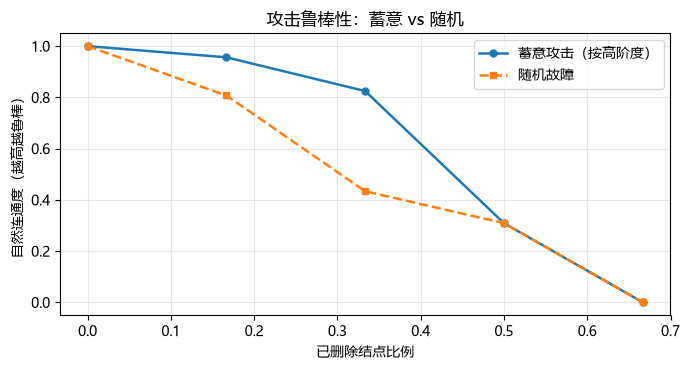

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for label, result, style in [
    ("蓄意攻击（按高阶度）", attack_degree, "-o"),
    ("随机故障", attack_random, "--s"),
]:
    data = next(iter(result.values()))
    ax.plot(data["steps"], data["nc_vals"], style, label=label, linewidth=1.8, markersize=5)

ax.set_xlabel("已删除结点比例")
ax.set_ylabel("自然连通度（越高越鲁棒）")
ax.set_title("攻击鲁棒性：蓄意 vs 随机")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 这个结果值得仔细看

直觉上"蓄意攻击枢纽"应该比"随机删"更致命。但本图的实际结果是
**随机攻击下降得更快**——看 33% 处：蓄意还剩 0.825，随机只剩 0.434。

为什么？因为这张图的枢纽是 `b`、`c`、`d`，而 `c`/`d` 恰好是**桥**。
度攻击先把桥拆掉，两个三角社区各自依然紧密，自然连通度掉得慢；
随机删反而更容易先削掉社区内部的结点，把三角打散。

**这不是 bug，是这个结构的真实性质。** 它说明一件事：
「按度排序」不等于「破坏力最强」——在模块化结构里，桥结点的度未必最高，
但删掉它们只是把网络切成两块，每块仍然健壮。

In [9]:
deg_data = next(iter(attack_degree.values()))
rnd_data = next(iter(attack_random.values()))


def nc_at(data: dict, fraction: float) -> float:
    """取某删除比例下的自然连通度（线性插值）。"""
    steps, vals = data["steps"], data["nc_vals"]
    for i in range(len(steps) - 1):
        if steps[i] <= fraction <= steps[i + 1]:
            span = steps[i + 1] - steps[i]
            if span == 0:
                return vals[i]
            return vals[i] + (fraction - steps[i]) / span * (vals[i + 1] - vals[i])
    return vals[-1]


print(f"{'删除比例':<10}{'蓄意':>8}{'随机':>8}{'随机-蓄意':>10}")
print("-" * 38)
for frac in (0.17, 0.33, 0.5):
    d = nc_at(deg_data, frac)
    r = nc_at(rnd_data, frac)
    print(f"{frac:<10.0%}{d:>8.3f}{r:>8.3f}{r - d:>+10.3f}")

print("\n差值为负 = 随机删后更脆弱 = 本图中随机攻击破坏更大")

删除比例            蓄意      随机     随机-蓄意
--------------------------------------
17%          0.954   0.800    -0.154
33%          0.827   0.441    -0.386
50%          0.309   0.309    +0.000

差值为负 = 随机删后更脆弱 = 本图中随机攻击破坏更大


## 5. 换成随机图再看一次

上一节的结论依赖「模块化 + 桥」这个特定结构。换成没有明显社区结构的
随机超图，蓄意攻击应当明显更致命——这是复杂网络理论的经典结论。

对比两个网络，能看出「结构决定鲁棒性」这件事。

In [10]:
H_random = honet.build.generate_random_hypernet(n_nodes=30, n_edges=40, max_edge_size=3, seed=7)
print("随机超图规模:", H_random.shape)

seq_d2 = honet.attack.degree_attack_sequence(H_random, target="node")
seq_r2 = honet.attack.random_attack_sequence(H_random, target="node", seed=42)
res_d2 = honet.attack.execute_attack(H_random, seq_d2, target="node")
res_r2 = honet.attack.execute_attack(H_random, seq_r2, target="node")

d2 = next(iter(res_d2.values()))
r2 = next(iter(res_r2.values()))

print(f"{'删除比例':<10}{'蓄意':>8}{'随机':>8}{'随机-蓄意':>10}")
print("-" * 38)
for frac in (0.2, 0.4, 0.6):
    dv = nc_at(d2, frac)
    rv = nc_at(r2, frac)
    print(f"{frac:<10.0%}{dv:>8.3f}{rv:>8.3f}{rv - dv:>+10.3f}")

随机超图规模: (29, 40)


删除比例            蓄意      随机     随机-蓄意
--------------------------------------
20%          1.707   2.112    +0.404
40%          0.810   1.232    +0.422
60%          0.216   0.517    +0.300


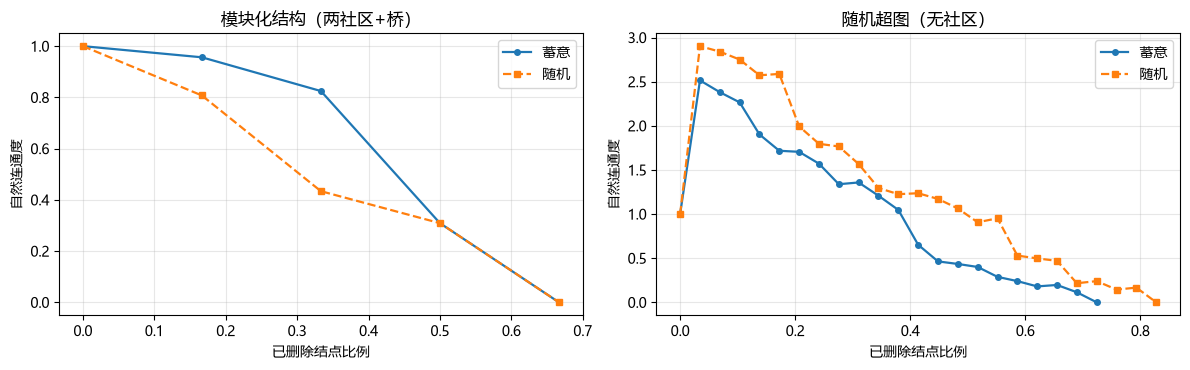

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

for ax, (title, res_d, res_r) in zip(
    axes,
    [
        ("模块化结构（两社区+桥）", attack_degree, attack_random),
        ("随机超图（无社区）", res_d2, res_r2),
    ],
    strict=True,
):
    for label, result, style in [("蓄意", res_d, "-o"), ("随机", res_r, "--s")]:
        data = next(iter(result.values()))
        ax.plot(data["steps"], data["nc_vals"], style, label=label, linewidth=1.6, markersize=4)
    ax.set_title(title)
    ax.set_xlabel("已删除结点比例")
    ax.set_ylabel("自然连通度")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 小结

| 需求 | 用哪个 |
| --- | --- |
| 自动切社区 | `basic_method` / `recursive_method` / `hierarchy_method` |
| 评估划分质量 | `extract_community_partition(H)["qh"]` |
| 批量比较多方法 | `compare_methods(H)` |
| 指定社区数 | `random_method(n_components=...)` / `nmf_method(...)` |
| 生成攻击顺序 | `degree_attack_sequence` / `centrality_attack_sequence` /
  `random_attack_sequence` |
| 执行并取曲线 | `execute_attack(H, sequence, target=...)` |

**三条关键提醒**：

1. **输入是 hypernetx 超图**。`honet.Hypergraph` 喂进去会报属性错误。
2. **`random_method` 是随机基线**，不是正经的社区发现算法。它的价值在于
   给其它方法一个「瞎猜也能到多少」的下界。
3. **必须同时跑蓄意攻击和随机故障**。只跑一条曲线看不出鲁棒性——
   两条曲线的**差距**才是结论。